In [1]:
import librosa
import numpy as np 

audio,sample_rate = librosa.load(
    "example.mp3",
    sr=None,
    mono=False
)

print("Audio:", audio)
print("Sampling Rate:", sample_rate)

Audio: [[ 0.0000000e+00 -7.3710982e-11 -1.0434402e-09 ... -2.9748298e-08
  -3.6357036e-08 -4.3044270e-08]
 [ 0.0000000e+00  6.2870886e-10  1.4240367e-09 ...  4.3450847e-09
   8.4525995e-09  7.8134716e-09]]
Sampling Rate: 44100


In [2]:
import soundfile as sf 

audio,sample_rate = sf.read("example.mp3")
print("Shape:", audio.shape)
print("Sampling Rate:", sample_rate)

Shape: (122112, 2)
Sampling Rate: 44100


In [3]:
from IPython.display import Audio, display

display(
    Audio(
        audio.T,
        rate=44100,
        normalize=False
    )
)

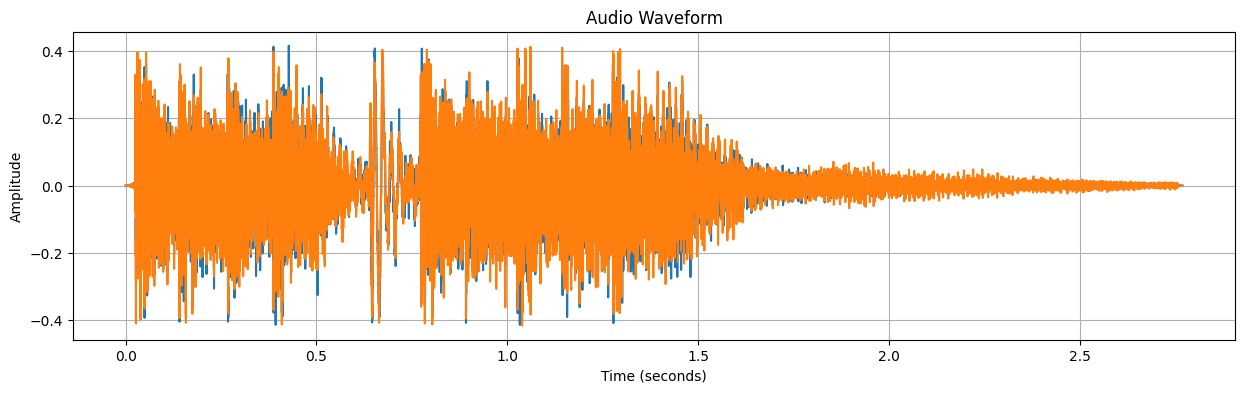

In [5]:
import matplotlib.pyplot as plt 

# Generate time axis
time = np.arange(len(audio)) / sample_rate

# Plot waveform
plt.figure(figsize=(15, 4))

plt.plot(time, audio)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Audio Waveform")

plt.grid()
plt.show()

In [6]:
# Identifying Silence

threshold = 0.02

silent_samples = np.abs(audio) < threshold

print("Silent samples:", np.sum(silent_samples))

Silent samples: 112577


In [7]:
# Higher RMS generally indicates greater signal energy.
# Lower RMS may indicate silence or a quiet region.

frame_size = 1024

rms_values = []

for start in range(0, len(audio), frame_size):

    frame = audio[start:start + frame_size]

    if len(frame) == 0:
        continue

    rms = np.sqrt(np.mean(frame ** 2))

    rms_values.append(rms)

rms_values = np.array(rms_values)

print(rms_values)

[1.21117150e-03 1.47146975e-01 1.26492671e-01 9.46592507e-02
 8.27430998e-02 7.27904598e-02 1.43898660e-01 1.05568063e-01
 9.57950641e-02 8.52762670e-02 8.47370738e-02 1.34348222e-01
 1.21569907e-01 8.54758687e-02 8.81302440e-02 7.93235457e-02
 1.19976793e-01 1.21891094e-01 1.07938381e-01 1.02067119e-01
 9.51915027e-02 9.23093776e-02 9.39801257e-02 5.95059725e-02
 5.48572786e-02 3.64194683e-02 3.30658681e-02 1.42404978e-01
 2.52362147e-01 1.43450588e-01 1.03912556e-01 4.83141549e-02
 4.12848075e-02 1.48447132e-01 1.24719342e-01 1.02654146e-01
 1.01790885e-01 8.55726752e-02 1.18936554e-01 9.87129713e-02
 9.18186621e-02 8.25015058e-02 8.70878409e-02 8.78060289e-02
 1.41747609e-01 1.19516277e-01 8.90189185e-02 6.79606083e-02
 7.45758590e-02 1.41962429e-01 1.06448051e-01 1.01239224e-01
 1.04758626e-01 9.36772735e-02 9.45864132e-02 1.61953030e-01
 1.03602138e-01 1.09540105e-01 8.92646524e-02 9.24461289e-02
 1.06539442e-01 1.03223304e-01 1.07607825e-01 9.17443907e-02
 7.47197258e-02 6.258887

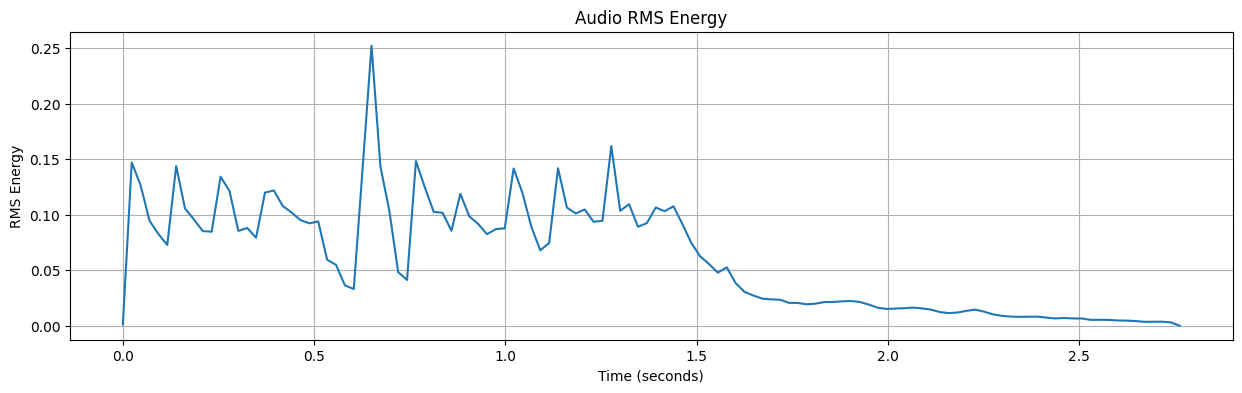

In [8]:
frame_times = (
    np.arange(len(rms_values))
    * frame_size
    / sample_rate
)

plt.figure(figsize=(15, 4))

plt.plot(frame_times, rms_values)

plt.xlabel("Time (seconds)")
plt.ylabel("RMS Energy")
plt.title("Audio RMS Energy")

plt.grid()
plt.show()

In [9]:
# Identifying Speech Regions

threshold = 0.02

speech_frames = rms_values > threshold

for i, is_speech in enumerate(speech_frames):

    if is_speech:
        print("Speech-like activity at:", frame_times[i])
    else:
        print("Low-energy region at:", frame_times[i])

Low-energy region at: 0.0
Speech-like activity at: 0.023219954648526078
Speech-like activity at: 0.046439909297052155
Speech-like activity at: 0.06965986394557823
Speech-like activity at: 0.09287981859410431
Speech-like activity at: 0.11609977324263039
Speech-like activity at: 0.13931972789115646
Speech-like activity at: 0.16253968253968254
Speech-like activity at: 0.18575963718820862
Speech-like activity at: 0.2089795918367347
Speech-like activity at: 0.23219954648526078
Speech-like activity at: 0.25541950113378686
Speech-like activity at: 0.2786394557823129
Speech-like activity at: 0.301859410430839
Speech-like activity at: 0.3250793650793651
Speech-like activity at: 0.34829931972789113
Speech-like activity at: 0.37151927437641724
Speech-like activity at: 0.3947392290249433
Speech-like activity at: 0.4179591836734694
Speech-like activity at: 0.44117913832199546
Speech-like activity at: 0.46439909297052157
Speech-like activity at: 0.4876190476190476
Speech-like activity at: 0.51083900

In [10]:
# Comparing Different Audio Recordings

audio1, sr1 = librosa.load(
    "example.mp3",
    sr=None
)

audio2, sr2 = librosa.load(
    "example1.mp3",
    sr=None
)

def inspect_audio(audio, sr):

    duration = len(audio) / sr

    peak = np.max(np.abs(audio))

    rms = np.sqrt(np.mean(audio ** 2))

    return {
        "Sampling Rate": sr,
        "Duration": duration,
        "Peak Amplitude": peak,
        "RMS Energy": rms
    }

print("Recording 1:", inspect_audio(audio1, sr1))
print("Recording 2:", inspect_audio(audio2, sr2))

Recording 1: {'Sampling Rate': 44100, 'Duration': 2.7689795918367346, 'Peak Amplitude': np.float32(0.40531296), 'RMS Energy': np.float32(0.07718328)}
Recording 2: {'Sampling Rate': 44100, 'Duration': 5.537959183673469, 'Peak Amplitude': np.float32(0.97046757), 'RMS Energy': np.float32(0.22649555)}


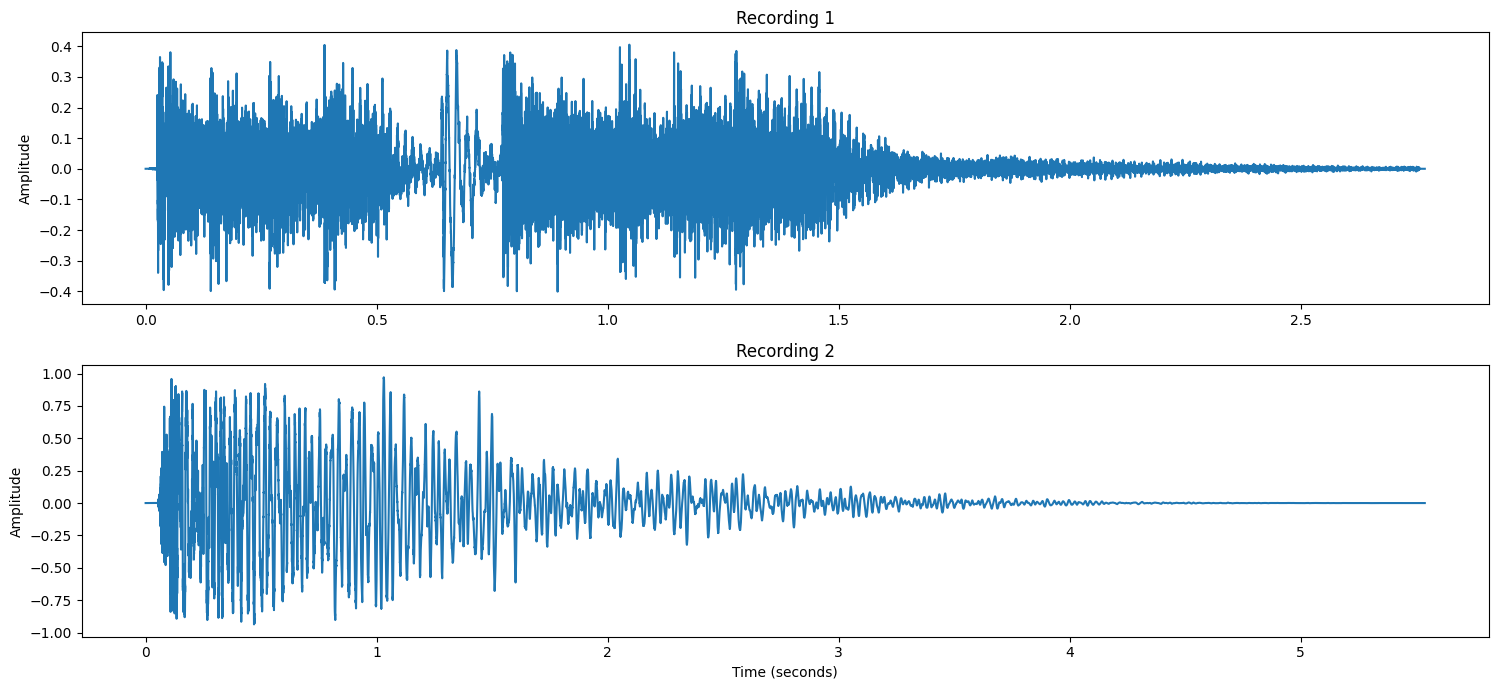

In [11]:
plt.figure(figsize=(15, 7))

plt.subplot(2, 1, 1)

time1 = np.arange(len(audio1)) / sr1

plt.plot(time1, audio1)

plt.title("Recording 1")
plt.ylabel("Amplitude")


plt.subplot(2, 1, 2)

time2 = np.arange(len(audio2)) / sr2

plt.plot(time2, audio2)

plt.title("Recording 2")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()

In [20]:
# Clipping and Distortion

clipping_threshold = 0.4

clipped_samples = np.abs(audio) >= clipping_threshold

clipped_count = np.sum(clipped_samples)

clipping_percentage = (
    clipped_count / len(audio)
) * 100

print("Clipped Samples:", clipped_count)

print("Clipping Percentage:", clipping_percentage)

Clipped Samples: 62
Clipping Percentage: 0.050773060796645696
